# 3. Transits and binning

Two knobs control the precision of a simulated observation:

- **`n_transits`** — how many transits are co-added. The noise tables store a
  single-transit depth uncertainty per wavelength channel; `observe()` scales
  it by 1/√N.
- **`R`** — the resolving power the model and noise are binned to. Coarser
  bins average more native channels together, so each bin is more precise but
  you resolve less structure.

This notebook shows both, then drops down to the `lazuli_exo.binning` module
that implements them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    plt.style.use("gks")
except OSError:
    pass

import lazuli_exo

print("terminator", lazuli_exo.__file__)

terminator /Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/terminator/src/lazuli_exo/__init__.py


## √N scaling

`depth_err` comes straight from the single-transit table divided by √N.
Nothing else changes — the model `depth` is identical.

In [2]:
PLANET = "WASP-39 b"
n_grid = np.array([1, 2, 5, 10, 20, 50])

obs1 = lazuli_exo.observe(PLANET, scenario="clear", n_transits=1, R=100)
errs = []
for n in n_grid:
    o = lazuli_exo.observe(PLANET, scenario="clear", n_transits=int(n), R=100)
    errs.append(np.median(o.depth_err))
    assert np.array_equal(o.depth, obs1.depth), "model must not change with N"

errs = np.array(errs)
ratio = errs[0] / errs

print(f"{'N':>4s}{'median sigma (ppm)':>22s}{'sigma_1/sigma_N':>18s}"
      f"{'sqrt(N)':>10s}")
for n, e, r in zip(n_grid, errs, ratio):
    print(f"{n:4d}{e * 1e6:22.2f}{r:18.4f}{np.sqrt(n):10.4f}")

assert np.allclose(ratio, np.sqrt(n_grid))
print("\nOK — errors scale exactly as 1/sqrt(N).")

   N    median sigma (ppm)   sigma_1/sigma_N   sqrt(N)
   1                 97.86            1.0000    1.0000
   2                 69.20            1.4142    1.4142
   5                 43.76            2.2361    2.2361
  10                 30.95            3.1623    3.1623
  20                 21.88            4.4721    4.4721
  50                 13.84            7.0711    7.0711

OK — errors scale exactly as 1/sqrt(N).


Because the statistic is linear in 1/σ, the template S/N inherits the same
scaling. This is the clearest illustration of what the model does *not*
include: there is no per-transit systematics term and no red-noise floor, so
the curve never flattens out.

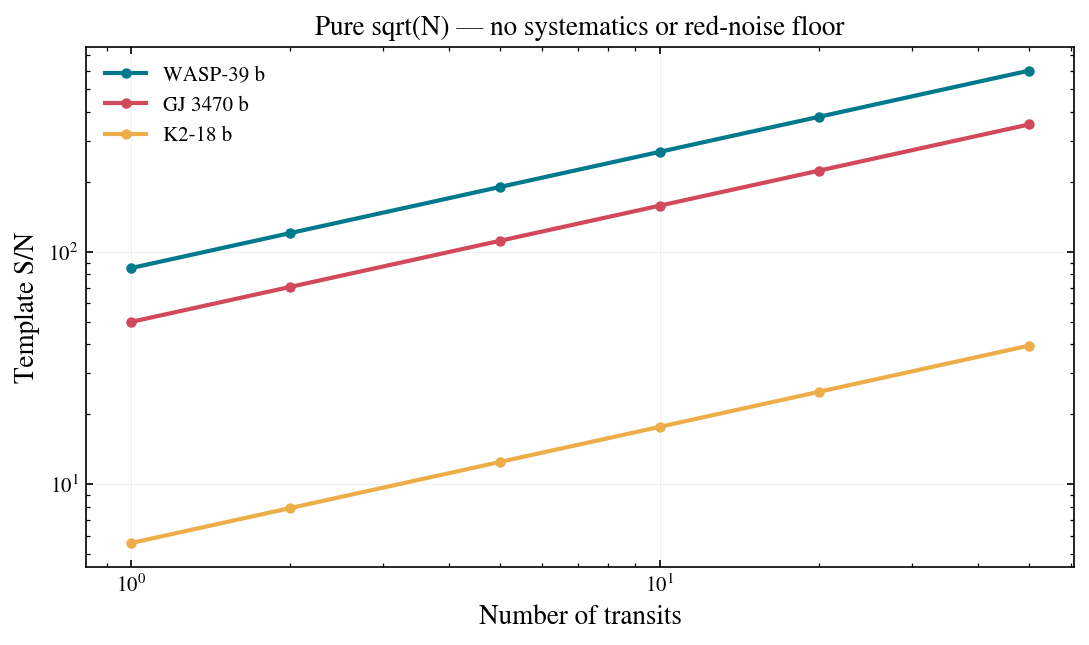

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))

for planet in ["WASP-39 b", "GJ 3470 b", "K2-18 b"]:
    snr = [lazuli_exo.observe(planet, scenario="clear", n_transits=int(n))
           .detect()["template_snr_diagonal"] for n in n_grid]
    ax.plot(n_grid, snr, "o-", ms=4, label=planet)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Number of transits")
ax.set_ylabel("Template S/N")
ax.set_title("Pure sqrt(N) — no systematics or red-noise floor")
ax.legend(frameon=False)
plt.show()

## What `R` can you actually ask for?

The ceiling is set by the noise tables: every requested bin must contain at
least one native noise channel. The binding constraint is the *coarsest*
part of the native grid, not its median.

In [4]:
from lazuli_exo import tables

tdir = tables.resolve_tables_dir(None)
wl_n, err_n, _ = tables.load_noise(tdir, PLANET)

native_R = wl_n[:-1] / np.diff(wl_n)
print(f"{wl_n.size} native noise channels over "
      f"[{wl_n.min():.4f}, {wl_n.max():.4f}] um")
print(f"native sampling R: min {native_R.min():.0f}, "
      f"median {np.median(native_R):.0f}, max {native_R.max():.0f}")
print(f"\n-> requesting much above R ~ {native_R.min():.0f} will empty a bin")

525 native noise channels over [0.4000, 1.6993] um
native sampling R: min 231, median 357, max 848

-> requesting much above R ~ 231 will empty a bin


## Choosing `R`

Coarser bins mean fewer, more precise points. The total template S/N is
roughly preserved as long as the bins still resolve the features — it only
degrades once a bin is wide enough to average a band's peak against its
continuum.

In [5]:
R_grid = [30, 50, 100, 150, 200]

print(f"{'R':>5s}{'bins':>7s}{'median sigma (ppm)':>22s}"
      f"{'template S/N':>15s}")
for R in R_grid:
    o = lazuli_exo.observe(PLANET, scenario="clear", n_transits=1, R=R)
    print(f"{R:5d}{o.wavelength.size:7d}{np.median(o.depth_err) * 1e6:22.2f}"
          f"{o.detect()['template_snr_diagonal']:15.1f}")

    R   bins    median sigma (ppm)   template S/N
   30     44                 53.56           80.6
   50     73                 68.93           83.4
  100    145                 97.86           85.2
  150    217                125.63           85.4
  200    290                142.61           85.0


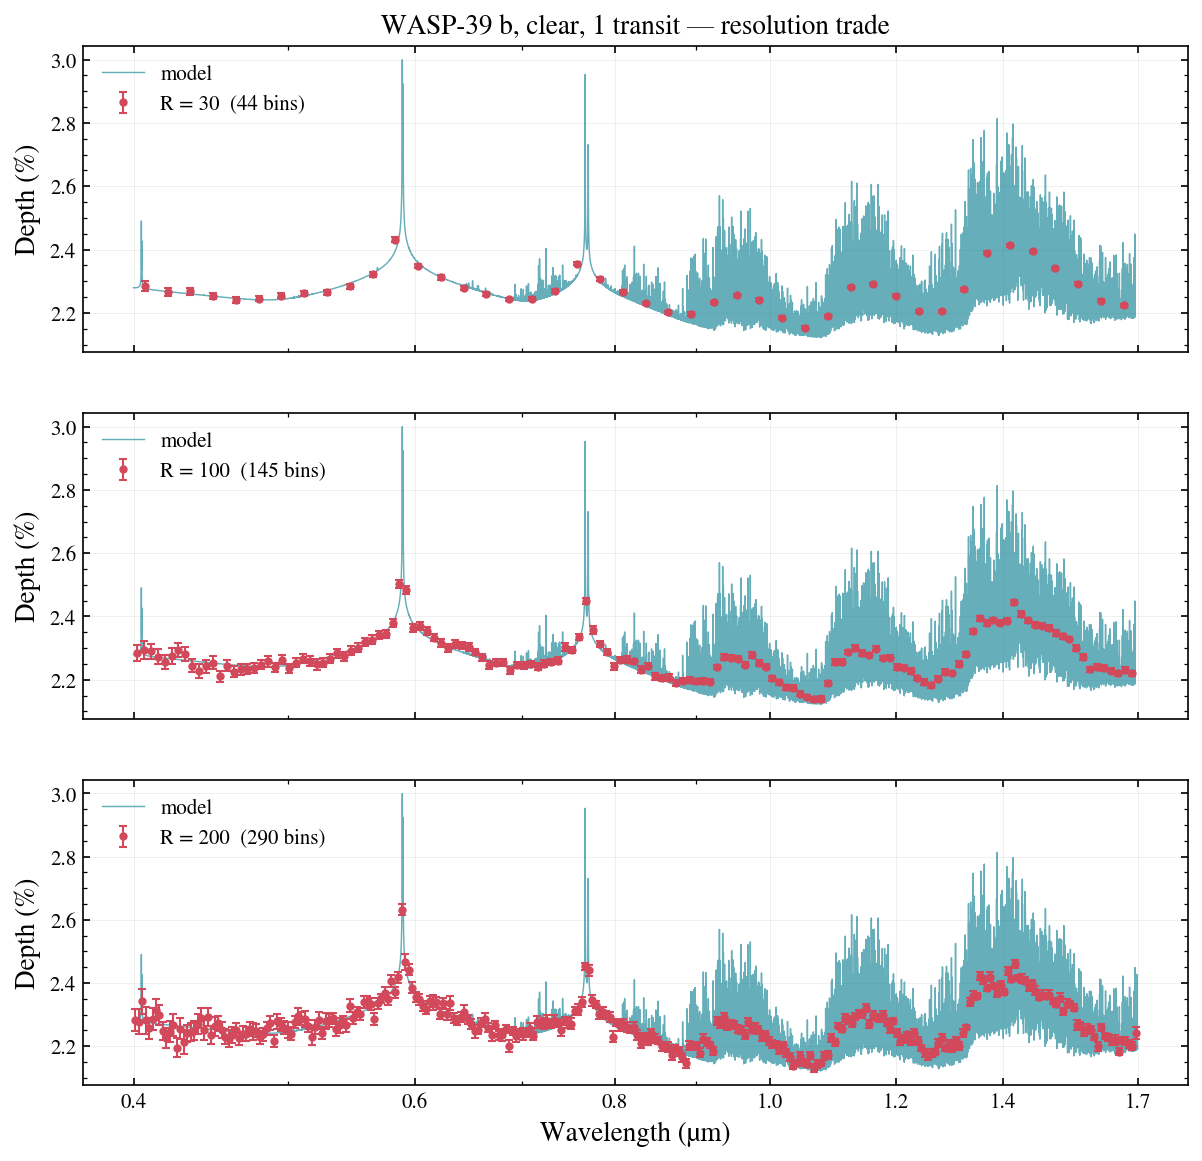

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(9.5, 9), sharex=True)

for ax, R in zip(axes, [30, 100, 200]):
    o = lazuli_exo.observe(PLANET, scenario="clear", n_transits=1, R=R)
    ax.plot(o.model_wavelength, o.model_depth * 100.0, lw=0.7, alpha=0.6,
            label="model")
    ax.errorbar(o.wavelength, o.simulate_points(seed=0) * 100.0,
                yerr=o.depth_err * 100.0, fmt="o", ms=3, lw=1, capsize=2,
                label=f"R = {R}  ({o.wavelength.size} bins)")
    ax.set_ylabel("Depth (%)")
    ax.legend(frameon=False, loc="upper left")

axes[-1].set_xscale("log")
axes[-1].set_xticks([0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.7])
axes[-1].get_xaxis().set_major_formatter(
    plt.matplotlib.ticker.ScalarFormatter())
axes[-1].set_xlabel("Wavelength (µm)")
axes[0].set_title(f"{PLANET}, clear, 1 transit — resolution trade")
plt.show()

## The binning module directly

`observe()` builds its grid with `lazuli_exo.binning`. The edges are
geometric, so every bin has the same fractional width 1 + 1/R.

In [7]:
from lazuli_exo import binning

edges = binning.constant_R_edges(0.40, 1.70, 100)
centers = binning.bin_centers(edges)

print(f"{len(centers)} complete bins over [{edges[0]:.4f}, "
      f"{edges[-1]:.4f}] um")
print(f"edge ratio: {edges[1] / edges[0]:.6f}  "
      f"(expected {1 + 1 / 100:.6f})")

frac = np.diff(edges) / centers
print(f"fractional width: constant at {frac.mean():.6f} "
      f"(spread {frac.std():.2e})")

# bin_centers is the geometric mean of the edges
assert np.allclose(centers, np.sqrt(edges[:-1] * edges[1:]))

145 complete bins over [0.4000, 1.6930] um
edge ratio: 1.010000  (expected 1.010000)
fractional width: constant at 0.009950 (spread 9.47e-17)


Only complete bins are kept, so the grid can stop up to one bin short of the
requested `wl_max` — worth knowing if you are matching grids between two
calls.

In [8]:
print(f"requested wl_max: 1.7000 um")
print(f"actual last edge:  {edges[-1]:.4f} um")
print(f"shortfall:         {(1.70 - edges[-1]) * 1e3:.2f} nm "
      f"(< one bin width of {np.diff(edges)[-1] * 1e3:.2f} nm)")

requested wl_max: 1.7000 um
actual last edge:  1.6930 um
shortfall:         6.99 nm (< one bin width of 16.76 nm)


`bin_model` averages the model samples in each bin. `bin_sigma` combines
noise channels in **inverse variance**, so the binned error shrinks roughly as
1/√(channels per bin) — that is where the precision gain from coarser `R`
comes from.

In [9]:
for R in [50, 100, 200]:
    e = binning.constant_R_edges(wl_n.min(), wl_n.max(), R)
    binned = binning.bin_sigma(wl_n, err_n, e)
    counts = np.bincount(np.digitize(wl_n, e) - 1,
                         minlength=len(e) - 1)[:len(e) - 1]
    print(f"R={R:4d}  channels/bin: median {np.median(counts):5.1f}   "
          f"binned sigma: median {np.median(binned) * 1e6:7.2f} ppm")

print(f"\nnative channels: {wl_n.size}, "
      f"native median sigma {np.median(err_n) * 1e6:.2f} ppm")

R=  50  channels/bin: median   6.0   binned sigma: median   68.93 ppm
R= 100  channels/bin: median   3.0   binned sigma: median   97.86 ppm
R= 200  channels/bin: median   2.0   binned sigma: median  142.61 ppm

native channels: 525, native median sigma 208.00 ppm


## When `R` is too high

Ask for more resolution than the noise tables actually sample and you get a
clear error naming the offending bin, rather than a silently empty one. Note
how close to the sampling limit you have to get — R = 400 is already too fine
for the blue end, where the native grid is coarsest.

In [10]:
try:
    lazuli_exo.observe(PLANET, scenario="clear", n_transits=1, R=400)
except ValueError as exc:
    print(f"ValueError: {exc}")
else:
    raise AssertionError("expected a ValueError")

ValueError: Bin 162 ([0.5994, 0.6009] um) contains no noise samples; requested R exceeds the native noise sampling


`n_transits` is validated too.

In [11]:
try:
    lazuli_exo.observe(PLANET, n_transits=0)
except ValueError as exc:
    print(f"ValueError: {exc}")
else:
    raise AssertionError("expected a ValueError")

ValueError: n_transits must be >= 1


## How many transits to reach a target S/N

A practical use of the √N scaling: invert it. Because the statistic is exactly
linear in √N, the number of transits needed to reach a target follows in
closed form from a single-transit run — no search required.

<div class="alert alert-warning">

These are **not** observing-time forecasts. The statistic is not a calibrated
significance, and the noise model has no systematics floor, so the real number
of transits would be larger — by an amount this model cannot tell you.

</div>

In [12]:
import warnings

TARGET_SNR = 100.0

rows = []
with warnings.catch_warnings():
    # three bright hosts warn about residual detector saturation;
    # see notebook 05 for what that means
    warnings.simplefilter("ignore", UserWarning)
    for p in lazuli_exo.list_planets():
        snr1 = lazuli_exo.observe(
            p, scenario="clear",
            n_transits=1).detect()["template_snr_diagonal"]
        rows.append((p, snr1, int(np.ceil((TARGET_SNR / snr1) ** 2))))

rows.sort(key=lambda r: r[2])
print(f"transits for template S/N = {TARGET_SNR:.0f}, clear scenario\n")
print(f"{'planet':14s}{'S/N (1 transit)':>17s}{'N needed':>11s}")
for p, snr1, n in rows:
    print(f"{p:14s}{snr1:17.2f}{n:11d}")

transits for template S/N = 100, clear scenario

planet          S/N (1 transit)   N needed
HD 209458 b              134.58          1
WASP-107 b               225.64          1
WASP-39 b                 85.17          2
HD 189733 b               69.28          3
WASP-121 b                63.33          3
GJ 3470 b                 49.98          5
GJ 1214 b                 42.53          6
WASP-12 b                 34.74          9
HAT-P-11 b                26.67         15
WASP-96 b                 22.99         19
TRAPPIST-1 e              18.72         29
TOI-270 d                 14.66         47
LHS 1140 b                11.43         77
K2-18 b                    5.59        320


In [13]:
# verify the closed form against an actual re-run for one target
p, snr1, n = rows[len(rows) // 2]
actual = lazuli_exo.observe(p, scenario="clear",
                            n_transits=n).detect()["template_snr_diagonal"]
print(f"{p}: predicted N={n} -> S/N {snr1 * np.sqrt(n):.3f}, "
      f"actual {actual:.3f}")
assert np.isclose(snr1 * np.sqrt(n), actual)
print("OK — the closed form is exact.")

WASP-12 b: predicted N=9 -> S/N 104.213, actual 104.213
OK — the closed form is exact.


## Summary

- `n_transits` scales `depth_err` by exactly 1/√N and nothing else; the model
  `depth` is untouched.
- Template S/N therefore grows as √N without limit — the model has no
  systematics or red-noise floor, which is its main unrealism here.
- `R` sets a geometric bin grid via `binning.constant_R_edges`; `bin_sigma`
  combines channels in inverse variance.
- Over-resolving raises a `ValueError` naming the offending bin.

Next: [light curves](04_light_curves.ipynb) — the time domain.